Importing Libraries

In [380]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re
from sklearn.cluster import KMeans

Importing the dataset : https://raw.githubusercontent.com/ShapeAI/Data-Analysis-and-Machine-Learning/main/Clustering%20Customer_segmentaion/Mall_Customers.csv

In [381]:
df=pd.read_csv('Mall_Customers.csv')

In [382]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Data Analysis

In [383]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [384]:
df.tail()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


In [385]:
df.shape

(200, 5)

In [386]:
df.info()
#Gender has dtype object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [387]:
df.isnull().sum()
# No null values

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [388]:
df.describe()


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Conclusion :
- Avg Age -> 38
- Age -> 15-70
- Avg Income -> $60k

Distribution of Age:

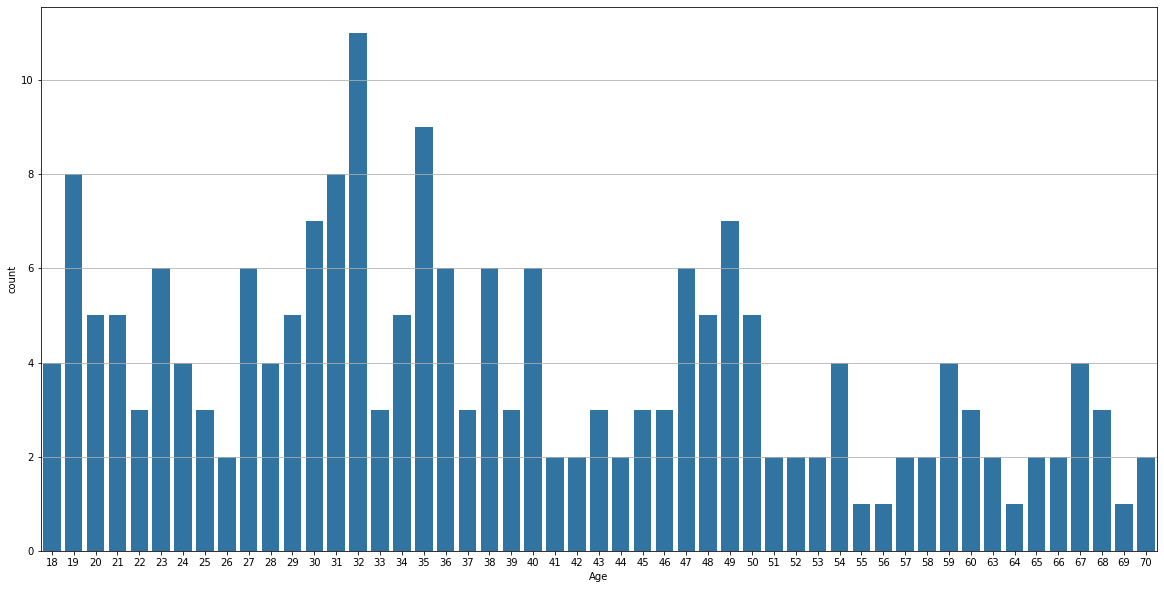

In [389]:
plt.figure(figsize=(20,10))
sns.countplot(data=df,x='Age')
plt.grid(axis='y')

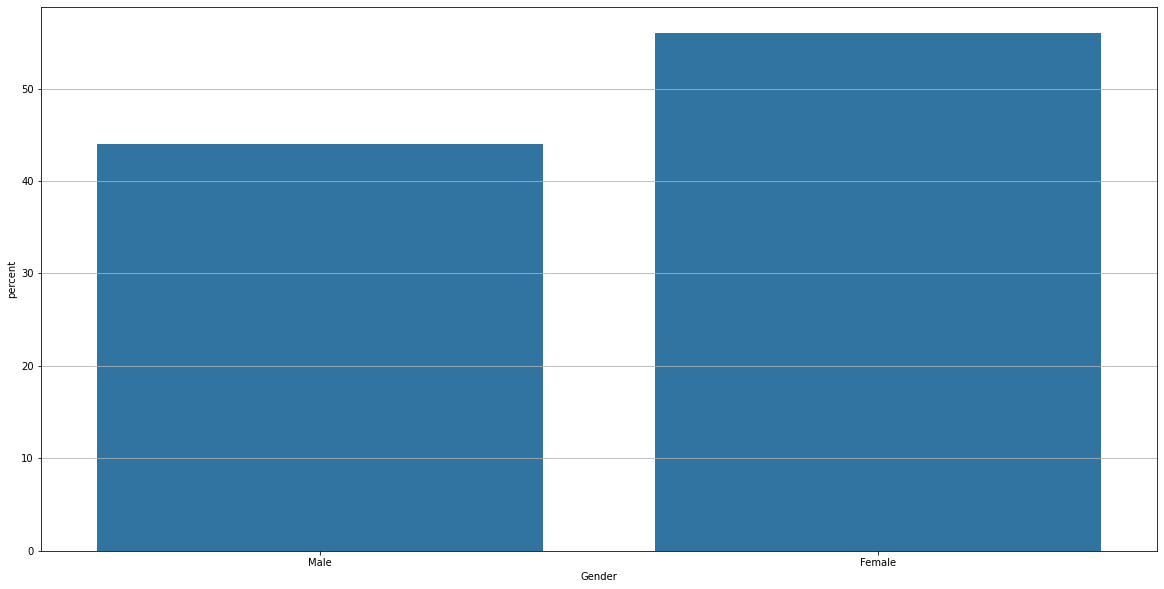

In [390]:
plt.figure(figsize=(20,10))
sns.countplot(data=df,x='Gender',stat='percent')
plt.grid(axis='y')

Pie chart for male and female

In [391]:
df.Gender.value_counts()

Gender
Female    112
Male       88
Name: count, dtype: int64

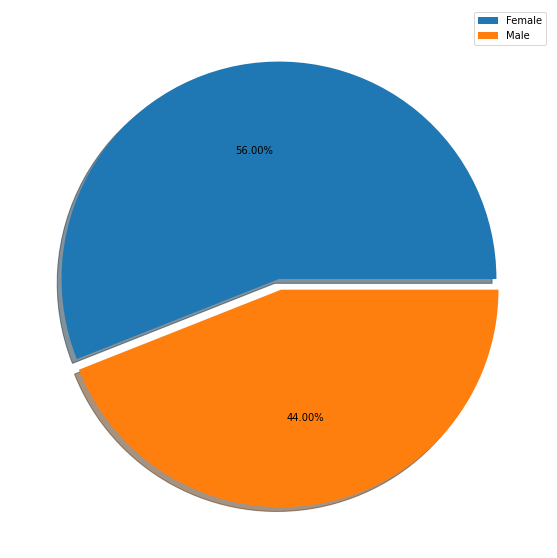

In [392]:
plt.figure(figsize=(20,10),facecolor='white')
plt.pie(df.Gender.value_counts(),autopct='%.2f%%',explode=(0,0.05),shadow=True)
plt.legend(df.Gender.value_counts().index)

Conclusion :
- Female customers are more
- Females 12% more than males

Distribution of Income

In [393]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Text(0.5, 1.0, 'Distribution of Annual Income')

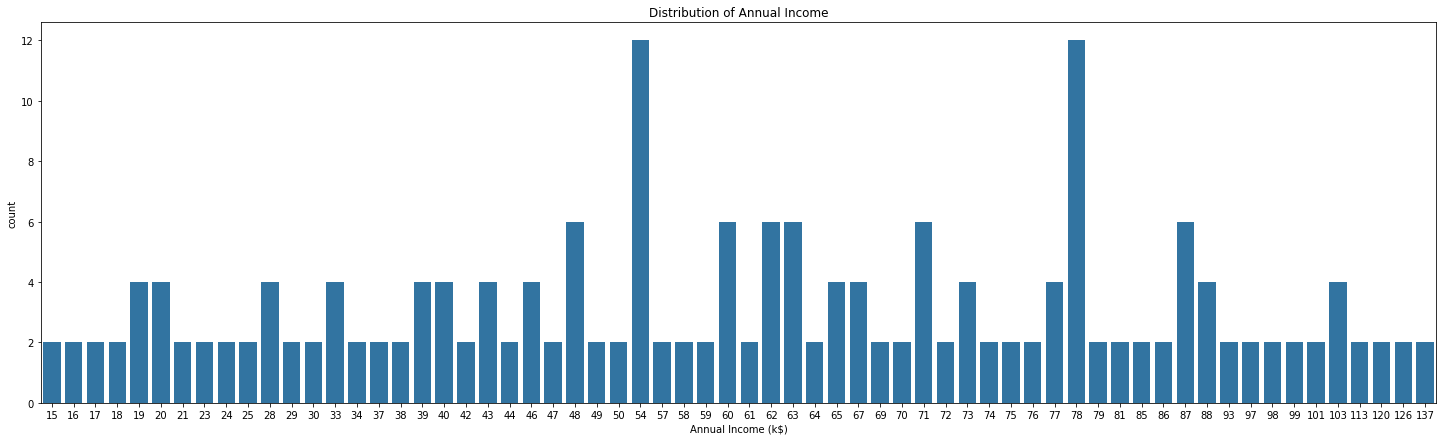

In [394]:
plt.figure(figsize=(25,7))
sns.countplot(data=df,x=df['Annual Income (k$)'])
plt.title("Distribution of Annual Income")

Conclusion :
- Customers having annual salary $54k and $78k visit the mall most often

Annual Income distribution wrt male and female

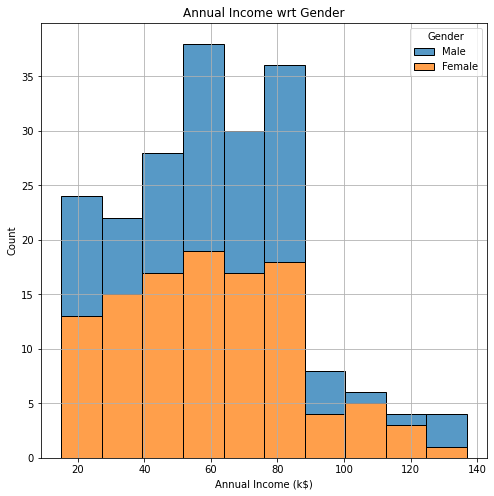

In [395]:
plt.figure(figsize=(8,8))
sns.histplot(data=df,x=df['Annual Income (k$)'],hue='Gender',multiple='stack')
plt.title('Annual Income wrt Gender')
plt.grid()

LM Plot

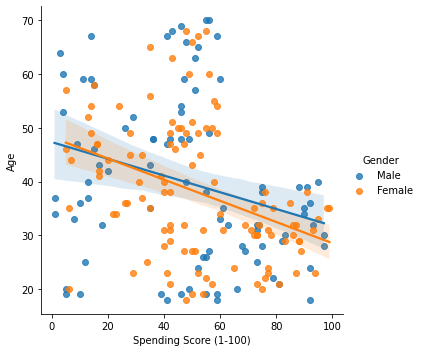

In [396]:
sns.lmplot(data=df,x='Spending Score (1-100)',y='Age',hue='Gender')

Machine Learning

In [397]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [398]:
df.drop(columns=['CustomerID'],axis=1,inplace=True)

In [399]:
df=pd.get_dummies(df,dtype=int,drop_first=True)

In [400]:
df.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male
0,19,15,39,1
1,21,15,81,1
2,20,16,6,0
3,23,16,77,0
4,31,17,40,0


K Mean Clustering

In [401]:
ssd=[]
for i in range(1,11): #cluster values : 1-10
    KModel=KMeans(n_clusters=i,n_init=15,max_iter=500)
    KModel.fit(df)
    ssd.append(KModel.inertia_)#WCSS value



In [402]:
ssd

[308862.05999999994,
 212889.442455243,
 143391.59236035674,
 104422.83498539748,
 75399.61541401484,
 58348.64136331505,
 51130.69008126377,
 44357.6215098352,
 40639.660394660765,
 37423.36593294263]

Text(0, 0.5, 'WCSS')

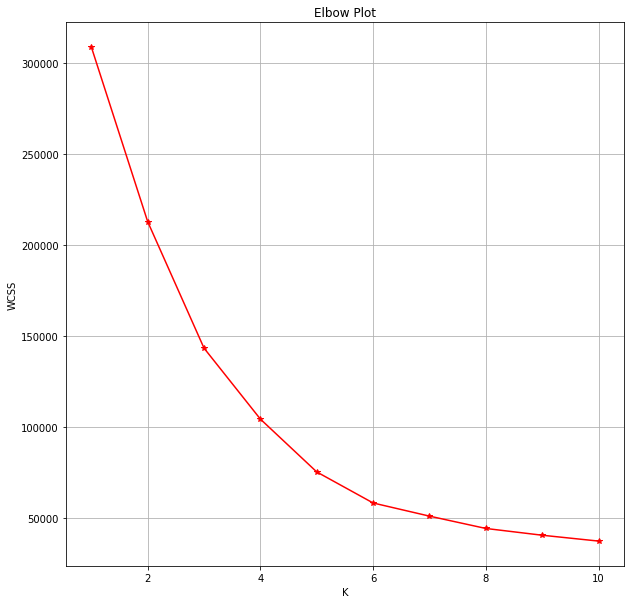

In [403]:
plt.figure(figsize=(10,10))
plt.plot(range(1,11),ssd,marker='*',color='red')
plt.grid()
plt.title("Elbow Plot")
plt.xlabel('K')
plt.ylabel("WCSS")

Since ssd(6)-ssd(7) is low, we take value of k=6

In [404]:
K_Model=KMeans(n_clusters=6,random_state=0)

In [405]:
pred=K_Model.fit_predict(df)

c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


In [406]:
pred

array([4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5,
       4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 3, 5, 3, 0,
       4, 5, 3, 0, 0, 0, 3, 0, 0, 3, 3, 3, 3, 3, 0, 3, 3, 0, 3, 3, 3, 0,
       3, 3, 0, 0, 3, 3, 3, 3, 3, 0, 3, 0, 0, 3, 3, 0, 3, 3, 0, 3, 3, 0,
       0, 3, 3, 0, 3, 0, 0, 0, 3, 0, 3, 0, 0, 3, 3, 0, 3, 0, 3, 3, 3, 3,
       3, 0, 0, 0, 0, 0, 3, 3, 3, 3, 0, 0, 0, 2, 0, 2, 1, 2, 1, 2, 1, 2,
       0, 2, 1, 2, 1, 2, 1, 2, 1, 2, 0, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2,
       1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2,
       1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2,
       1, 2])

In [407]:
K_Model.cluster_centers_

array([[27.        , 56.65789474, 49.13157895,  0.34210526],
       [41.68571429, 88.22857143, 17.28571429,  0.57142857],
       [32.69230769, 86.53846154, 82.12820513,  0.46153846],
       [56.15555556, 53.37777778, 49.08888889,  0.44444444],
       [44.14285714, 25.14285714, 19.52380952,  0.38095238],
       [25.27272727, 25.72727273, 79.36363636,  0.40909091]])

In [408]:
df['Clusters']=pred

In [409]:
df.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male,Clusters
0,19,15,39,1,4
1,21,15,81,1,5
2,20,16,6,0,4
3,23,16,77,0,5
4,31,17,40,0,4


In [410]:
df.Clusters.value_counts()

Clusters
3    45
2    39
0    38
1    35
5    22
4    21
Name: count, dtype: int64

Clusters:

<Axes: xlabel='Annual Income (k$)', ylabel='Spending Score (1-100)'>

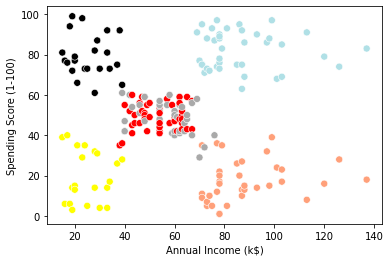

In [412]:
color = np.array(['darkgray', 'lightsalmon', 'powderblue', 'red', 'yellow', 'black'])
sns.scatterplot(x = df['Annual Income (k$)'],
                y = df['Spending Score (1-100)'],
                c=color[K_Model.labels_],
                s=50)

Hierarchical Clusters

In [ ]:
from scipy.cluster.hierarchy import linkage,dendrogram

In [ ]:
var=linkage(df,method='ward')

Text(0.5, 1.0, 'dendrogram')

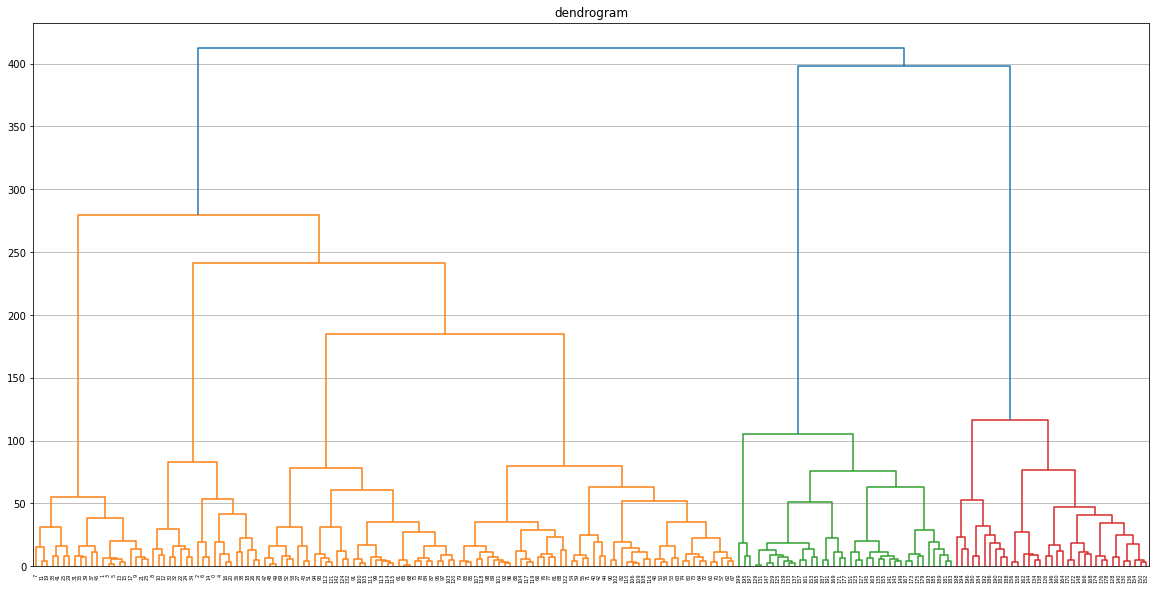

In [ ]:
plt.figure(figsize=(20,10))
dendrogram(var,leaf_rotation=90)
plt.grid(axis='y')
plt.title("dendrogram")